In [4]:
dataset = "https://drive.google.com/file/d/1j2KECVojfawF6tI1ZcYBuB0L_w1ydkPo/view?usp=sharing"

print(f"Link to Dataset  : {dataset}")

Link to Dataset  : https://drive.google.com/file/d/1j2KECVojfawF6tI1ZcYBuB0L_w1ydkPo/view?usp=sharing


In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OrdinalEncoder,OneHotEncoder,LabelEncoder,StandardScaler,MinMaxScaler,RobustScaler

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

from sklearn.linear_model import LinearRegression,SGDRegressor
from sklearn.metrics import mean_squared_error,r2_score,root_mean_squared_error,mean_absolute_error
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score,precision_score,recall_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import classification_report, confusion_matrix



###Perform EDA using appropriate charts and basic descriptive statistics.
###Select your top 3 features and justify your choices using visual and statistical evidence.
###For each selected feature, explain in simple terms why it intuitively affects income.
###Rank your 3 features from most important to least important, provide why you think that ?


In [6]:
df = pd.read_csv("adult_income.csv")
df.info()
print(df.describe())
u_workclass = df['workclass'].unique()
u_education = df['education'].unique()
u_marital_status = df['marital-status'].unique()
u_relationship = df['relationship'].unique()
u_race = df['race'].unique()
u_sex = df['sex'].unique()
u_native_country = df['native-country'].unique()
u_income = df['income'].unique()
print(f"wc{u_workclass} \n edu {u_education} \n mar {u_marital_status} \n rltn {u_relationship} \n race {u_race} \n sex {u_sex} \n country {u_native_country} \n income {u_income}")
df['income'] = df['income'].str.strip()
df['income'] = df['income'].replace('<=50K.', '<=50K')
df['income'] = df['income'].replace('>50K.', '>50K')
df['native-country'] = df['native-country'].replace(' ?', np.nan)
df['workclass'] = df['workclass'].replace(' ?', np.nan)
df['occupation'] = df['occupation'].replace(' ?', np.nan)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             48842 non-null  int64 
 1   workclass       48842 non-null  object
 2   fnlwgt          48842 non-null  int64 
 3   education       48842 non-null  object
 4   education-num   48842 non-null  int64 
 5   marital-status  48842 non-null  object
 6   occupation      48842 non-null  object
 7   relationship    48842 non-null  object
 8   race            48842 non-null  object
 9   sex             48842 non-null  object
 10  capital-gain    48842 non-null  int64 
 11  capital-loss    48842 non-null  int64 
 12  hours-per-week  48842 non-null  int64 
 13  native-country  48842 non-null  object
 14  income          48842 non-null  object
dtypes: int64(6), object(9)
memory usage: 5.6+ MB
                age        fnlwgt  education-num  capital-gain  capital-loss  \
count  48842.

In [7]:
# df.isnull().sum()
(df['capital-gain']>0).sum()
# df.sample(1000)

# df.sample(1000)
# df.describe()

np.int64(4035)

<Axes: xlabel='income', ylabel='count'>

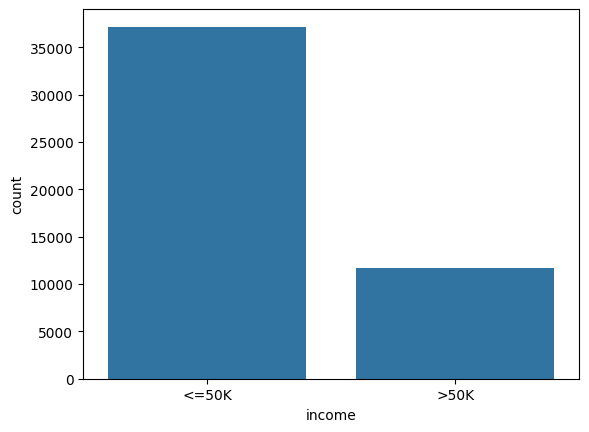

In [8]:
sns.countplot(data = df, x = df['income'])

<Axes: xlabel='count', ylabel='workclass'>

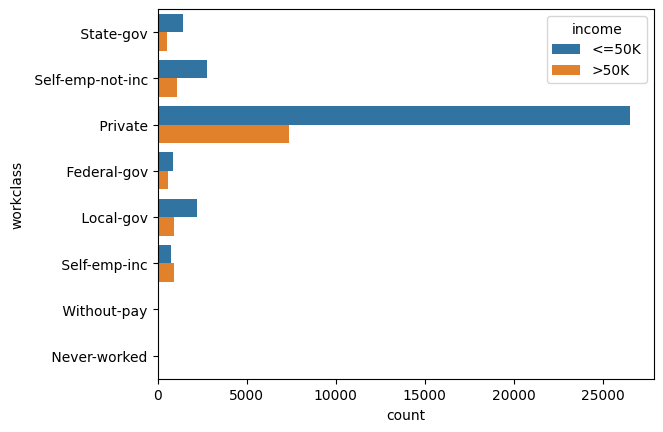

In [9]:
sns.countplot(y=df['workclass'],hue=df['income'])

<Axes: xlabel='count', ylabel='education'>

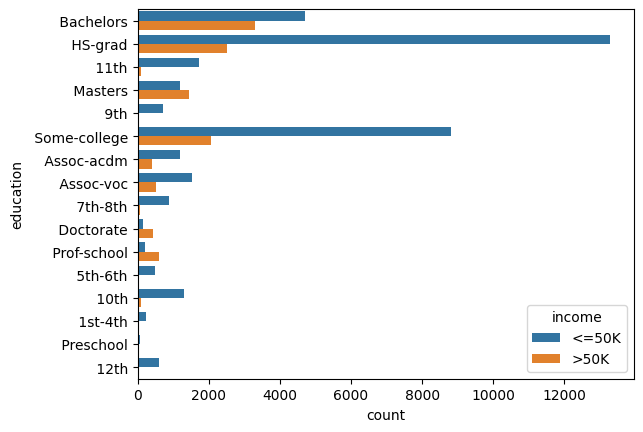

In [10]:
sns.countplot(y=df['education'],hue=df['income'])

<Axes: xlabel='count', ylabel='marital-status'>

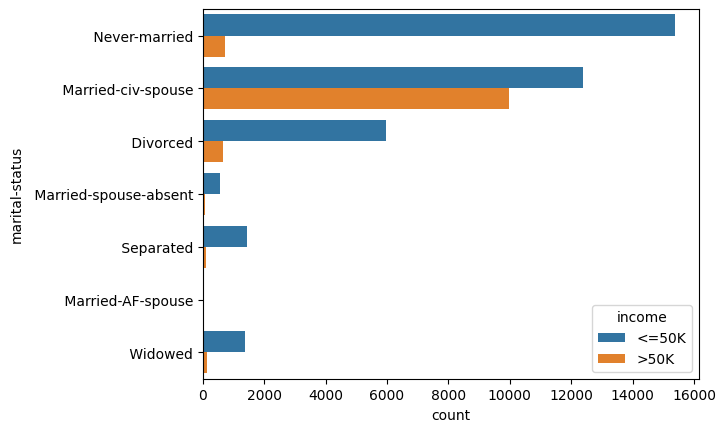

In [11]:
sns.countplot(y=df['marital-status'],hue=df['income'])

<Axes: xlabel='count', ylabel='relationship'>

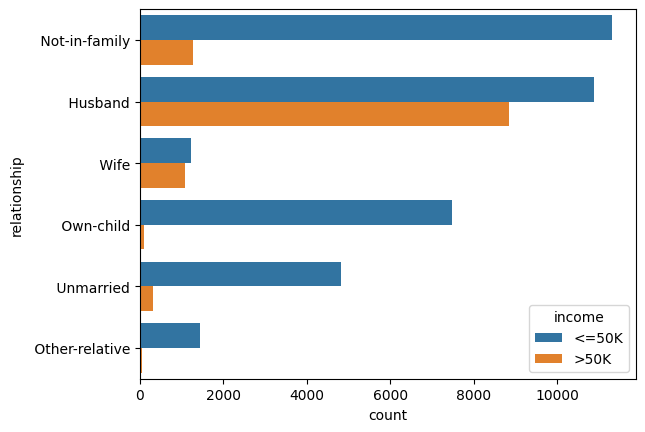

In [12]:
sns.countplot(y=df['relationship'],hue=df['income'])

<Axes: xlabel='count', ylabel='race'>

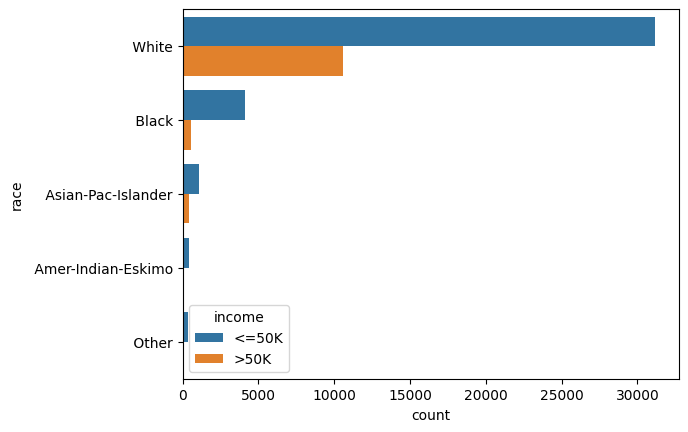

In [13]:
sns.countplot(y=df['race'],hue=df['income'])

<Axes: xlabel='count', ylabel='sex'>

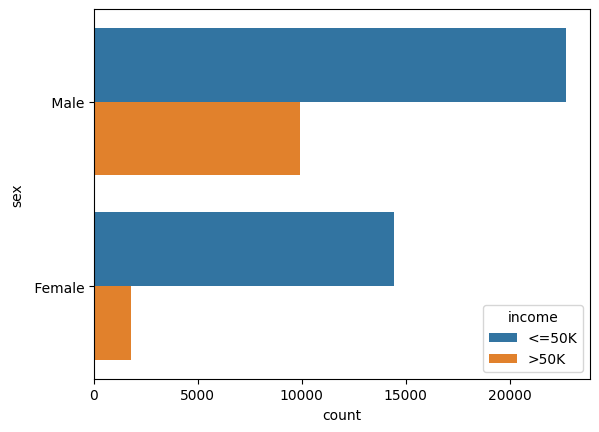

In [14]:
sns.countplot(y=df['sex'],hue=df['income'])

<Axes: xlabel='count', ylabel='native-country'>

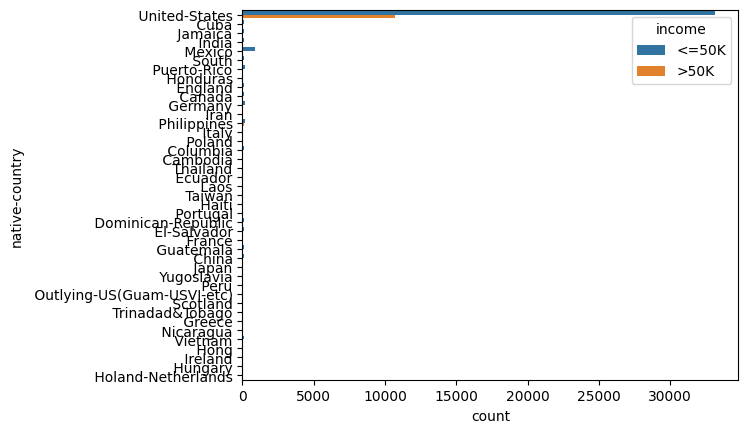

In [15]:
sns.countplot(y=df['native-country'],hue=df['income'])

In [16]:
edu_grp = df.groupby('education')['income'].value_counts(normalize=True)
race_grp = df.groupby('race')['income'].value_counts(normalize=True)
sex_grp = df.groupby('sex')['income'].value_counts(normalize=True)
relation_grp = df.groupby('relationship')['income'].value_counts(normalize=True)
mstat_grp = df.groupby('marital-status')['income'].value_counts(normalize=True)
wclass_grp = df.groupby('workclass')['income'].value_counts(normalize=True)
occu_grp = df.groupby('occupation')['income'].value_counts(normalize=True)

print(f"edu_grp: {edu_grp} \n")
print("\n")
print(f"race_grp: {race_grp} \n")
print("\n")
print(f"sex_grp: {sex_grp} \n")
print("\n")
print(f"relation_grp: {relation_grp} \n")
print("\n")
print(f"mstat_grp: {mstat_grp} \n")
print("\n")
print(f"wclass_grp: {wclass_grp} \n")
print("\n")
print(f"occu_grp: {occu_grp} \n")
print("\n")

edu_grp: education     income
10th          <=50K     0.937365
              >50K      0.062635
11th          <=50K     0.949227
              >50K      0.050773
12th          <=50K     0.926941
              >50K      0.073059
1st-4th       <=50K     0.967611
              >50K      0.032389
5th-6th       <=50K     0.946955
              >50K      0.053045
7th-8th       <=50K     0.935079
              >50K      0.064921
9th           <=50K     0.945767
              >50K      0.054233
Assoc-acdm    <=50K     0.742036
              >50K      0.257964
Assoc-voc     <=50K     0.746725
              >50K      0.253275
Bachelors     <=50K     0.587165
              >50K      0.412835
Doctorate     >50K      0.725589
              <=50K     0.274411
HS-grad       <=50K     0.841422
              >50K      0.158578
Masters       >50K      0.549116
              <=50K     0.450884
Preschool     <=50K     0.987952
              >50K      0.012048
Prof-school   >50K      0.739808
             

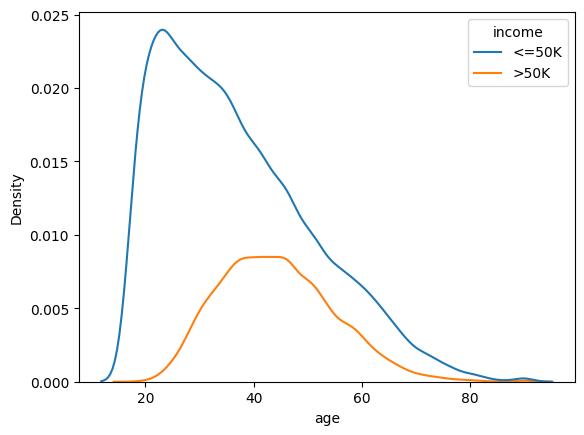

In [17]:
sns.kdeplot(data=df, x='age', hue='income')
plt.show()

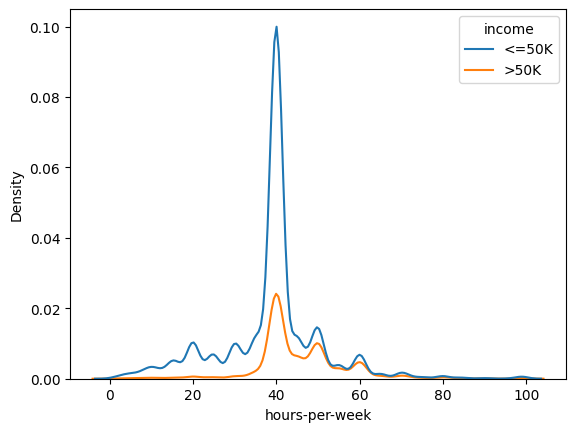

In [18]:
sns.kdeplot(data=df, x='hours-per-week', hue='income')
plt.show()

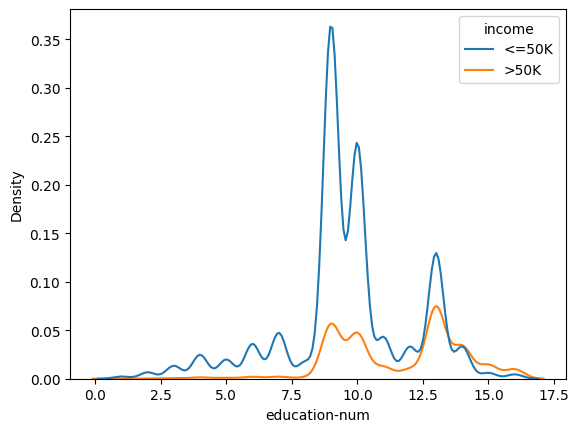

In [19]:
sns.kdeplot(data = df, x = 'education-num', hue = 'income')
plt.show()

In [20]:
edu_grp = df.groupby('education-num')['income'].value_counts(normalize=True)
age_grp = df.groupby('age')['income'].value_counts(normalize=True)
hour_grp = df.groupby('hours-per-week')['income'].value_counts(normalize=True)
gain_grp = df.groupby('capital-gain')['income'].value_counts(normalize=True)
loss_grp = df.groupby('capital-loss')['income'].value_counts(normalize=True)

print(f"edu_grp: {edu_grp} \n")
print("\n")
print(f"age_grp: {age_grp} \n")
print("\n")
print(f"hour_grp: {hour_grp} \n")
print("\n")
print(f"gain_grp: {gain_grp} \n")
print("\n")
print(f"loss_grp: {loss_grp} \n")

edu_grp: education-num  income
1              <=50K     0.987952
               >50K      0.012048
2              <=50K     0.967611
               >50K      0.032389
3              <=50K     0.946955
               >50K      0.053045
4              <=50K     0.935079
               >50K      0.064921
5              <=50K     0.945767
               >50K      0.054233
6              <=50K     0.937365
               >50K      0.062635
7              <=50K     0.949227
               >50K      0.050773
8              <=50K     0.926941
               >50K      0.073059
9              <=50K     0.841422
               >50K      0.158578
10             <=50K     0.810351
               >50K      0.189649
11             <=50K     0.746725
               >50K      0.253275
12             <=50K     0.742036
               >50K      0.257964
13             <=50K     0.587165
               >50K      0.412835
14             >50K      0.549116
               <=50K     0.450884
15             >5

## Feature Analysis

* For the **income** object, there were initially 4 classes due to string spaces. These were converted into 2 classes. Some columns, such as **country** and **region**, contained `'?'`, which had to be considered as `NaN` initially. **Capital Gain** and **Capital Loss** had around 4,000 values among 48,000 data points, but where the data was present, it showed some significance. For example, if **Capital Gain** was more than 7,000, it was almost always in the `>50K` category. Overall, the two classes were also not balanced.

* **Education-num** and **Education** had the highest significance. From the KDE plot of **Education-num**, it can be seen that as the education level increases, the percentage of `>50K` increases, particularly starting from 11 onwards. For the categorical **Education** column:

| Education  | Income | Percentage |
| ---------- | ------ | ---------: |
| Assoc-acdm | <=50K  |   0.742036 |
| Assoc-acdm | >50K   |   0.257964 |
| Assoc-voc  | <=50K  |   0.746725 |
| Assoc-voc  | >50K   |   0.253275 |
| Bachelors  | <=50K  |   0.587165 |
| Bachelors  | >50K   |   0.412835 |
| Doctorate  | >50K   |   0.725589 |
| Doctorate  | <=50K  |   0.274411 |
| Masters    | >50K   |   0.549116 |
| Masters    | <=50K  |   0.450884 |

This shows that **Education** has high significance.

* **Relationship** and **Marital Status** also played a significant role. A clear distinction can be seen from the following percentages:

| Marital Status / Relationship | Income | Percentage |
| ----------------------------- | ------ | ---------: |
| Married-AF-spouse             | <=50K  |   0.621622 |
| Married-AF-spouse             | >50K   |   0.378378 |
| Married-civ-spouse            | <=50K  |   0.553867 |
| Married-civ-spouse            | >50K   |   0.446133 |
| Married-spouse-absent         | <=50K  |   0.907643 |
| Married-spouse-absent         | >50K   |   0.092357 |
| Never-married                 | <=50K  |   0.954520 |
| Never-married                 | >50K   |   0.045480 |

The same goes for the **Relationship** and **Marital Status** sections, where clear differences between the two income classes can be observed.

* The **Occupation** group has the most balanced distribution of the two classes. Thus, it is considered one of the most important features.

### Intuitive Interpretation

* Intuitively, **Education** is supposed to have more significance, as it can result in better job quality in the future.
* **Occupation** is also important because different job sectors have different pay scales by norm.
* **Marital Status/Relationship** should also have an impact, as generally, people who have a family or are part of a family earn to provide for the family.

## Feature Selection

Based on the above analysis, I selected the following features in order of importance:

1. **Education and Education-num** — These were considered the top features because they showed the most impact according to the distribution.

2. **Marital Status and Relationship** — These were considered the second most important features, as some categories showed a marginally higher impact than others in these two columns.

3. **Occupation** — This was considered the third most important feature because it has a very good distribution of both classes, and different occupations show significance in income.



###Design Scikit-Learn Pipelines that handles missing values, categorical feature encoding, and numerical feature scaling.
###Documentation: Clearly explain what specific preprocessing steps you applied to which columns and why you chose those specific methods.


In [21]:
# X = df.drop(['hours-per-week','capital-gain', 'capital-loss'], axis = 1)
X = df.drop(['hours-per-week'], axis = 1)
y = df['hours-per-week']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

numeric_cols = ['age', 'education-num', 'fnlwgt']
# numeric_cols = ['age', 'education-num']
gain_loss_cols = ['capital-gain', 'capital-loss']
cat_cols = ['education', 'workclass', 'sex', 'income', 'marital-status', 'relationship', 'occupation', 'race', 'native-country']
# cat_cols = ['education', 'workclass', 'sex', 'income', 'marital-status', 'relationship', 'occupation']
num_transformers = Pipeline([
    ('imputer', SimpleImputer(strategy='mean')),
    ('scaler', StandardScaler())
])

gain_loss_transformers = Pipeline([
    ('imputer', SimpleImputer(strategy='mean')),
    ('scaler', StandardScaler())
])

cat_transformers = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(sparse_output=False, drop = 'first', handle_unknown='ignore'))
])
# ('gain_loss', gain_loss_transformers, gain_loss_cols),
preprocessor = ColumnTransformer([
    ('num', num_transformers, numeric_cols),
    ('gain_loss', gain_loss_transformers, gain_loss_cols),
    ('cat', cat_transformers, cat_cols)
], verbose_feature_names_out = False)

## Data Preprocessing

* For the **categorical columns**, I used `most_frequent` as the imputation strategy. I used **One-Hot Encoding** with `drop='first'` to keep the number of columns minimal while encoding the different unique values.

* As the dataset was quite balanced, I used **mean imputation** and **StandardScaler** for the numerical columns.

* For the **Capital Gain** and **Capital Loss** columns, I initially used **median imputation** and **RobustScaler**. However, this became problematic for **Gradient Descent**, as around 3,000–4,000 values were between approximately 1,000 and 9,000, while the remaining values were directly 0. Therefore, I later imputed these columns using the **mean strategy** and used **StandardScaler**. I also tried **MinMaxScaler**, which gave similar results.



Regression Modeling & Evaluation

####Train a standard Linear Regression model using your pipeline.
####Train a Stochastic Gradient Descent (SGD) Regressor model using your pipeline.
####Evaluate and compare both models using R2, MAE, and MSE.
####Briefly discuss which model performed better and why.


In [22]:


SGD_pipe = Pipeline(
    steps = [
        ('preprocessor', preprocessor),
        ('model', SGDRegressor())
    ]
)
SGD_pipe.fit(X_train, y_train)
SGD_pred = SGD_pipe.predict(X_test)
print("\n SDG: \n")
print(f"MSE: {round(mean_squared_error(y_test, SGD_pred), 4)}")
print(f"R2: {round(r2_score(y_test, SGD_pred), 4)}")
print(f"MAE: {round(mean_absolute_error(y_test, SGD_pred), 4)}")

lr_pipe = Pipeline(
    steps = [
        ('preprocessor', preprocessor),
        ('model', LinearRegression())
    ]
)

lr_pipe.fit(X_train, y_train)
lr_pred = lr_pipe.predict(X_test)
print("\n LR: \n")
print(f"MSE: {round(mean_squared_error(y_test, lr_pred), 4)}")
print(f"R2: {round(r2_score(y_test, lr_pred), 4)}")
print(f"MAE: {round(mean_absolute_error(y_test, lr_pred), 4)}")


/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [8] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(



 SDG: 

MSE: 123.4335
R2: 0.1949
MAE: 7.6865

 LR: 

MSE: 123.3139
R2: 0.1957
MAE: 7.6746


/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [8] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


For SGD and LR, both performed almost similar with LR performing **very little** better in MSE and R2. The results are almost identical, and in this scenario, both algorithms predicted almost the same.

**Problem Statement:**
Shift your focus from regression back to classification. Build an end-to-end Logistic Regression pipeline to predict whether a person earns more than $50K annually ( income feature)
**Tasks:**
#####Construct a new Scikit-Learn Pipeline that includes your new preprocessing steps and a Logistic Regression classifier.
#####Train the model and evaluate its performance on a test set using Accuracy, Precision, and Recall.


In [23]:
X = df.drop(['income'], axis=1)
y = df['income']
lb_encoder = LabelEncoder()
y = lb_encoder.fit_transform(y)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42 )

numeric_cols = ['age', 'education-num', 'fnlwgt', 'capital-gain', 'capital-loss', 'hours-per-week']
cat_cols = ['education', 'workclass', 'sex', 'marital-status', 'relationship', 'occupation', 'race', 'native-country']

num_transformers = Pipeline([
    ('imputer', SimpleImputer(strategy='mean')),
    ('scaler', StandardScaler())
])

cat_transformers = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(sparse_output=False, drop='first', handle_unknown='ignore'))
])


preprocessor = ColumnTransformer([
    ('num', num_transformers, numeric_cols),
    ('cat', cat_transformers, cat_cols)
], verbose_feature_names_out=False)

logReg_pipe = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('model', LogisticRegression(class_weight='balanced', max_iter=1000))
    ]
)

logReg_pipe.fit(X_train, y_train)

logReg_pred = logReg_pipe.predict(X_test)

accuracy = accuracy_score(y_test, logReg_pred)
precision = precision_score(y_test, logReg_pred)
recall = recall_score(y_test, logReg_pred)
print(f"Accuracy: {accuracy}")
print(f"Precision: {precision}")
print(f"Recall: {recall}")

Accuracy: 0.8068379568021292
Precision: 0.5667808219178082
Recall: 0.8433121019108281


/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [7] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


**Hyperparameter Tuning & Model Comparison**

#####Use GridSearchCV to systematically tune a KNN Classifier on hyperparameters: n_neighbors, weights, and metric.


#####Once the optimal KNN model is found, evaluate it using Accuracy, Precision, and Recall.


#####Comparison: Compare the performance metrics of your Tuned KNN model against the default Logistic Regression model. Which algorithm performed better overall.







In [24]:
knn_pipe = Pipeline([
    ('preprocessor', preprocessor),
    ('knn', KNeighborsClassifier())
])

grid = {
    # 'knn__n_neighbors': [3,7,11,15,19],
    'knn__n_neighbors': [19,23,27,31],
    'knn__weights': ['distance', 'uniform'],
    'knn__p': [1,2]
}

grid_search = GridSearchCV(
    estimator = knn_pipe,
    param_grid = grid,
    cv = 5
)

grid_search.fit(X_train, y_train)


GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('preprocessor',
                                        ColumnTransformer(transformers=[('num',
                                                                         Pipeline(steps=[('imputer',
                                                                                          SimpleImputer()),
                                                                                         ('scaler',
                                                                                          StandardScaler())]),
                                                                         ['age',
                                                                          'education-num',
                                                                          'fnlwgt',
                                                                          'capital-gain',
                                                                          'capital-loss',
                                                                          'hours-per-week']),
                                                                        ('cat',
                                                                         Pipeline(steps=[('imputer',
                                                                                          SimpleImputer(strategy='most_frequent')),
                                                                                         ('encoder',
                                                                                          OneHotEncoder(drop='first',
                                                                                                        handle_unknown='ignore',
                                                                                                        sparse_output=False))]),
                                                                         ['education',
                                                                          'workclass',
                                                                          'sex',
                                                                          'marital-status',
                                                                          'relationship',
                                                                          'occupation',
                                                                          'race',
                                                                          'native-country'])],
                                                          verbose_feature_names_out=False)),
                                       ('knn', KNeighborsClassifier())]),
             param_grid={'knn__n_neighbors': [19, 23, 27, 31], 'knn__p': [1, 2],
                         'knn__weights': ['distance', 'uniform']})

In [25]:
print(grid_search.best_params_)
knn_model = grid_search.best_estimator_
# print(knn_model)
y_pred_knn = knn_model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred_knn)
print(f"Accuracy {accuracy} \n")
print("Classification Report \n")
print(classification_report(y_test, y_pred_knn))

{'knn__n_neighbors': 31, 'knn__p': 2, 'knn__weights': 'uniform'}


/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [7] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


Accuracy 0.8443034087419388 

Classification Report 

              precision    recall  f1-score   support

           0       0.88      0.92      0.90      7414
           1       0.71      0.60      0.65      2355

    accuracy                           0.84      9769
   macro avg       0.79      0.76      0.77      9769
weighted avg       0.84      0.84      0.84      9769



## Model Performance Comparison

* Overall accuracy was better for **KNN**, at **84%**, compared to **Logistic Regression**, which achieved **80.7%** accuracy.

* **Logistic Regression** had a better **Recall** score of **84%**, but its **Precision** was lower. However, when I changed the classification threshold to **60% or 70%**, the Recall declined while Precision increased.

* For the **optimally tuned KNN**, the **Precision** was better at **71%** compared to Logistic Regression with the default **0.5 threshold**.
